# SonicCaption — Notebook 03: Speech Recognition, Sequence Modelling & Timeline Fusion
**MAI522-5 Speech Processing & Recognition · Member 2 (Speech & Fusion Lead)**

| § | Topic | Syllabus |
|---|---|---|
| 1 | Build a demo clip: speech + applause + door knock | — |
| 2 | **Voice activity detection** with Silero VAD | Unit 3 (speech detection) |
| 3 | **Speech recognition** with Whisper + **WER / CER** by edit-distance dynamic programming | Units 3–4 |
| 4 | **Sound events** with the team's ESC-50 classifier (sliding window) | Unit 2–3 |
| 5 | **Discrete HMM**: forward evaluation and **Viterbi** trellis decoding | Unit 4 |
| 6 | **Dual-stream timeline fusion** → final captions and `.srt` | Product |

The backend modules (`audio/vad.py`, `services/asr_service.py`, `services/sound_cnn.py`, `algorithms/hmm.py`,
`timeline/fusion.py`) are written out from this notebook with `%%writefile`, so the notebook and the app run *the same code*.

**Run:** Colab or Kaggle, internet on. GPU not needed. Optional: a `GROQ_API_KEY` secret for fast hosted Whisper;
without it, Whisper runs locally (slower, but free and offline-capable).

## 0. Setup

In [1]:
!pip install -q silero-vad faster-whisper

In [3]:
import os, sys, json, re, urllib.request
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, librosa, soundfile as sf

# Optional: Groq key from Colab / Kaggle secrets (hosted Whisper). Without it, local faster-whisper is used.
if not os.environ.get("GROQ_API_KEY"):
    try:
        from google.colab import userdata; os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY") or ""
    except Exception:
        try:
            from kaggle_secrets import UserSecretsClient; os.environ["GROQ_API_KEY"] = UserSecretsClient().get_secret("GROQ_API_KEY")
        except Exception:
            pass
if not os.environ.get("GROQ_API_KEY"):
    os.environ.pop("GROQ_API_KEY", None)
print("ASR provider:", "Groq hosted Whisper" if os.environ.get("GROQ_API_KEY") else "local faster-whisper")

# Which sound model to use: "resnet" = Member 1's ResNet-18 (team default), "cnn" = 5-fold CNN backup on Hugging Face
SOUND_MODEL = "resnet"

SR = 16000
DATA, FIG = Path("data_03"), Path("figures"); DATA.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
for d in ["audio", "services", "algorithms", "timeline"]:
    Path(f"sc_pkg/soniccaption/{d}").mkdir(parents=True, exist_ok=True)
sys.path.insert(0, "sc_pkg")

def fetch(url, path):
    path = Path(path)
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

ASR provider: Groq hosted Whisper


## 1. Demo clip
- **Speech:** JFK's 1961 inaugural address excerpt — the public-domain test clip shipped with OpenAI's Whisper repository,
  with a known reference transcript (used for WER).
- **Sounds:** a clapping clip and a door-knock clip from ESC-50 **fold 5** (CC BY-NC; K. J. Piczak).

Layout: `1 s silence | speech (11 s) | applause (5 s) | door knock (5 s) | 1 s silence`

Demo clip: 23.0 s
   ground truth  start  end
        silence    0.0  1.0
         speech    1.0 12.0
       clapping   12.0 17.0
door_wood_knock   17.0 22.0
        silence   22.0 23.0


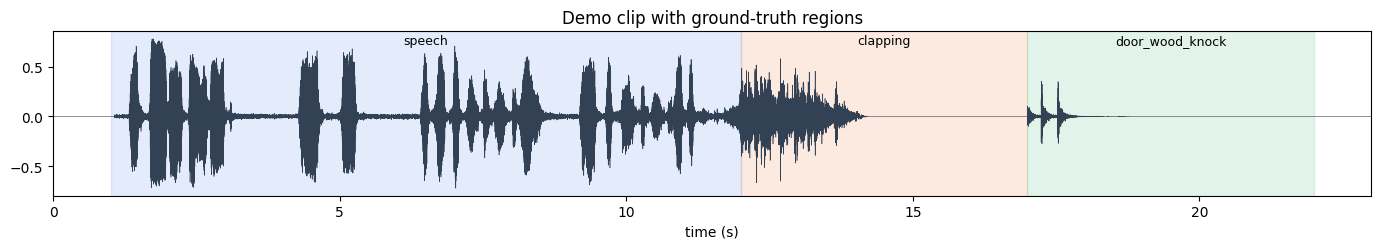

In [4]:
JFK_REF = "And so my fellow Americans, ask not what your country can do for you, ask what you can do for your country."
ESC = "https://raw.githubusercontent.com/karolpiczak/ESC-50/master/audio/"
jfk_path = fetch("https://raw.githubusercontent.com/openai/whisper/main/tests/jfk.flac", DATA / "jfk.flac")
clap_path = fetch(ESC + "5-218494-A-22.wav", DATA / "clapping.wav")
knock_path = fetch(ESC + "5-218980-A-30.wav", DATA / "door_knock.wav")

load = lambda p: librosa.load(p, sr=SR, mono=True)[0]
speech, clap, knock = load(jfk_path), load(clap_path), load(knock_path)
sil = np.zeros(SR, np.float32)
pieces = [("silence", sil), ("speech", speech), ("clapping", clap), ("door_wood_knock", knock), ("silence", sil)]
demo = np.concatenate([p for _, p in pieces]).astype(np.float32)

truth, t = [], 0.0
for name, p in pieces:
    truth.append((name, round(t, 2), round(t + len(p) / SR, 2))); t += len(p) / SR
sf.write(DATA / "demo_clip.wav", demo, SR)
DURATION = len(demo) / SR
print(f"Demo clip: {DURATION:.1f} s"); print(pd.DataFrame(truth, columns=["ground truth", "start", "end"]).to_string(index=False))

fig, ax = plt.subplots(figsize=(14, 2.6))
ax.plot(np.arange(len(demo)) / SR, demo, lw=0.4, color="#334155")
for name, s, e in truth:
    if name != "silence":
        ax.axvspan(s, e, alpha=0.12, color={"speech": "#2563eb", "clapping": "#ea580c", "door_wood_knock": "#16a34a"}[name])
        ax.text((s + e) / 2, ax.get_ylim()[1] * 0.85, name, ha="center", fontsize=9)
ax.set_xlabel("time (s)"); ax.set_title("Demo clip with ground-truth regions"); ax.set_xlim(0, DURATION)
plt.tight_layout(); plt.show()

## 2. Voice activity detection (Silero VAD)
VAD answers **where** someone is speaking (ASR answers **what** was said).
Silero VAD is a small pretrained neural network that outputs a speech probability for every 32 ms frame (512 samples at 16 kHz).
Frames with probability ≥ *threshold* are speech; gaps shorter than `min_silence_ms` are bridged, bursts shorter than
`min_speech_ms` are discarded, and each segment is padded by `pad_ms`.

Unlike a simple short-time-energy + zero-crossing-rate detector (Unit 1), it is not fooled by loud non-speech such as applause.

In [5]:
%%writefile sc_pkg/soniccaption/audio/vad.py
"""Voice activity detection (Unit 3: speech detection) using the pretrained Silero VAD model.

VAD answers *where* someone is speaking; ASR answers *what* they said.
Silero is a small neural network that scores every 32 ms frame (512 samples at 16 kHz) with a
speech probability; frames above `threshold` are grouped into segments, short gaps are bridged
and very short bursts are dropped.

Contract:
    detect_speech(audio, sample_rate) -> [{"start": float, "end": float}, ...]   (seconds, sorted)
"""
from __future__ import annotations

import warnings
from functools import lru_cache

import numpy as np

VAD_SAMPLE_RATE = 16000          # Silero supports 8 kHz and 16 kHz; the project standard is 16 kHz
_MIN_SAMPLES = 512               # one Silero frame


@lru_cache(maxsize=1)
def _load_model():
    """Load Silero VAD once (the weights ship inside the `silero-vad` pip package, no download)."""
    from silero_vad import load_silero_vad
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", FutureWarning)
        return load_silero_vad()


def _prepare(audio: np.ndarray, sample_rate: int) -> np.ndarray:
    audio = np.asarray(audio, dtype=np.float32)
    if audio.ndim == 2:                                   # (channels, samples) or (samples, channels)
        audio = audio.mean(axis=0 if audio.shape[0] < audio.shape[1] else 1)
    if audio.ndim != 1:
        raise ValueError(f"Expected mono or stereo audio, got shape {audio.shape}.")
    if sample_rate <= 0:
        raise ValueError(f"Invalid sample rate {sample_rate}.")
    if not np.all(np.isfinite(audio)):
        raise ValueError("Audio contains NaN or infinite values.")
    if sample_rate != VAD_SAMPLE_RATE:
        import librosa
        audio = librosa.resample(audio, orig_sr=sample_rate, target_sr=VAD_SAMPLE_RATE)
    peak = np.max(np.abs(audio)) if audio.size else 0.0
    if peak > 1.0:                                        # int16-style input -> [-1, 1]
        audio = audio / peak
    return audio.astype(np.float32)


def detect_speech(audio: np.ndarray, sample_rate: int, threshold: float = 0.5,
                  min_speech_ms: int = 250, min_silence_ms: int = 100, pad_ms: int = 30) -> list[dict]:
    """Return speech segments in seconds, sorted by start time.

    threshold       speech probability needed to count a frame as speech (higher = stricter)
    min_speech_ms   drop speech bursts shorter than this
    min_silence_ms  gaps shorter than this do not split a segment
    pad_ms          padding added to both ends of every segment
    """
    if not 0.0 < threshold < 1.0:
        raise ValueError("threshold must be between 0 and 1.")
    x = _prepare(audio, sample_rate)
    if x.size < _MIN_SAMPLES or np.max(np.abs(x)) < 1e-4:   # too short or digital silence
        return []

    import torch
    from silero_vad import get_speech_timestamps
    stamps = get_speech_timestamps(torch.from_numpy(x), _load_model(), threshold=threshold,
                                   sampling_rate=VAD_SAMPLE_RATE, min_speech_duration_ms=min_speech_ms,
                                   min_silence_duration_ms=min_silence_ms, speech_pad_ms=pad_ms,
                                   return_seconds=False)
    duration = x.size / VAD_SAMPLE_RATE
    segments = [{"start": round(max(0.0, s["start"] / VAD_SAMPLE_RATE), 3),
                 "end": round(min(duration, s["end"] / VAD_SAMPLE_RATE), 3)} for s in stamps]
    return sorted((s for s in segments if s["end"] > s["start"]), key=lambda s: s["start"])


def speech_ratio(segments: list[dict], duration: float) -> float:
    """Fraction of the clip that contains speech (the `vad_speech_ratio` metric)."""
    if duration <= 0:
        return 0.0
    return round(min(1.0, sum(s["end"] - s["start"] for s in segments) / duration), 3)

Writing sc_pkg/soniccaption/audio/vad.py


VAD speech segments: [{'start': 1.314, 'end': 3.23}, {'start': 4.29, 'end': 4.83}, {'start': 4.962, 'end': 5.406}, {'start': 6.402, 'end': 8.606}, {'start': 9.186, 'end': 11.518}]
Speech ratio: 0.323


/tmp/ipykernel_2742/767757434.py:11: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  probs = [float(vad_model(torch.from_numpy(demo[i:i + 512]), SR)) for i in range(0, len(demo) - 511, 512)]


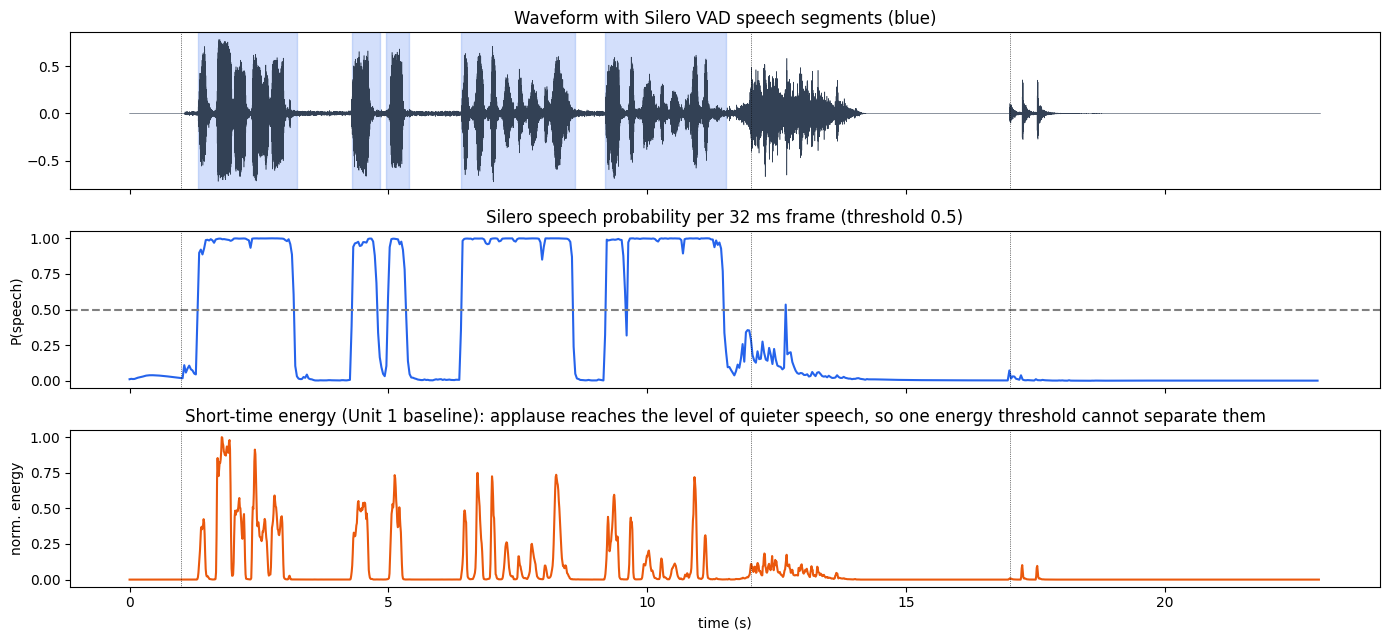

In [6]:
from soniccaption.audio.vad import detect_speech, speech_ratio
import torch

vad_segments = detect_speech(demo, SR)
print("VAD speech segments:", vad_segments)
print("Speech ratio:", speech_ratio(vad_segments, DURATION))

# frame-level probabilities for the figure
from soniccaption.audio.vad import _load_model
vad_model = _load_model(); vad_model.reset_states()
probs = [float(vad_model(torch.from_numpy(demo[i:i + 512]), SR)) for i in range(0, len(demo) - 511, 512)]
tp = np.arange(len(probs)) * 512 / SR

# energy-based baseline for comparison (Unit 1 short-time energy)
frame, hop = 400, 160
energy = np.array([np.sum(demo[i:i + frame] ** 2) for i in range(0, len(demo) - frame, hop)])
te = np.arange(len(energy)) * hop / SR

fig, axes = plt.subplots(3, 1, figsize=(14, 6.5), sharex=True)
axes[0].plot(np.arange(len(demo)) / SR, demo, lw=0.4, color="#334155")
for s in vad_segments: axes[0].axvspan(s["start"], s["end"], color="#2563eb", alpha=0.2)
axes[0].set_title("Waveform with Silero VAD speech segments (blue)")
axes[1].plot(tp, probs, color="#2563eb"); axes[1].axhline(0.5, ls="--", color="gray"); axes[1].set_ylabel("P(speech)")
axes[1].set_title("Silero speech probability per 32 ms frame (threshold 0.5)")
axes[2].plot(te, energy / energy.max(), color="#ea580c"); axes[2].set_ylabel("norm. energy")
axes[2].set_title("Short-time energy (Unit 1 baseline): applause reaches the level of quieter speech, so one energy threshold cannot separate them")
axes[2].set_xlabel("time (s)")
for ax in axes:
    for name, s, e in truth:
        if name != "silence": ax.axvline(s, color="k", lw=0.5, ls=":")
plt.tight_layout(); plt.savefig(FIG / "fig_vad_segments.png", dpi=200); plt.show()

## 3. Speech recognition with Whisper
Whisper is a **pretrained** encoder–decoder Transformer from OpenAI (log-Mel input → encoder → autoregressive text decoder).
**The team does not train it**; we call it through one adapter with two providers:
hosted `whisper-large-v3-turbo` on Groq, or local `faster-whisper` on CPU as the fallback.
Both return the same JSON: segments with start/end times and word timestamps.

In [7]:
%%writefile sc_pkg/soniccaption/services/asr_service.py
"""Speech-to-text (ASR) adapter.

Whisper is a *pretrained* model (OpenAI); the team does not train it. Two providers sit behind one contract:

    GroqASRProvider          hosted Whisper via the Groq API (fast; needs GROQ_API_KEY; audio leaves the machine)
    FasterWhisperProvider    local Whisper on CPU via faster-whisper (offline fallback; slower)

Contract (from the implementation plan):
    transcribe_audio(audio_path, language=None) -> {
        "text": str,
        "segments": [{"start": float, "end": float, "text": str,
                      "words": [{"start": float, "end": float, "word": str}]}],
        "provider": str,            # "groq-whisper" or "faster-whisper"
        "language": str | None,
        "warnings": [str],          # e.g. why the fallback was used
    }

The UI and timeline must not depend on which provider ran.
"""
from __future__ import annotations

import io
import os
import time
from functools import lru_cache
from pathlib import Path

import numpy as np

ASR_SAMPLE_RATE = 16000
GROQ_URL = "https://api.groq.com/openai/v1/audio/transcriptions"
GROQ_MODEL = os.environ.get("GROQ_WHISPER_MODEL", "whisper-large-v3-turbo")
LOCAL_MODEL = os.environ.get("FASTER_WHISPER_MODEL", "base")
# 16 kHz mono 16-bit WAV is 32 kB/s, so 10-minute chunks (~19 MB) stay under Groq's 25 MB free-tier limit.
GROQ_CHUNK_SECONDS = 600


class ASRError(RuntimeError):
    """Raised when no provider could transcribe the audio; the message is safe to show in the UI."""


# ----------------------------------------------------------------------------- helpers
def _load_audio(audio_path: str | Path) -> np.ndarray:
    path = Path(audio_path)
    if not path.is_file():
        raise ASRError(f"Audio file not found: {path.name}")
    import librosa
    try:
        y, _ = librosa.load(str(path), sr=ASR_SAMPLE_RATE, mono=True)
    except Exception as e:  # noqa: BLE001 - decoding errors come from several libraries
        raise ASRError(f"Could not decode {path.name}: {e}") from e
    return y.astype(np.float32)


def _wav_bytes(y: np.ndarray) -> bytes:
    import soundfile as sf
    buf = io.BytesIO()
    sf.write(buf, y, ASR_SAMPLE_RATE, format="WAV", subtype="PCM_16")
    return buf.getvalue()


def _attach_words(segments: list[dict], words: list[dict]) -> None:
    """Groq returns words as one flat list; give each segment the words whose midpoint falls inside it."""
    for seg in segments:
        seg["words"] = [w for w in words if seg["start"] <= (w["start"] + w["end"]) / 2 < seg["end"] + 1e-6]


def _clean(result: dict) -> dict:
    """Round times, strip text, drop empty segments and sort - identical output for every provider."""
    segs = []
    for s in result["segments"]:
        text = s["text"].strip()
        if not text:
            continue
        segs.append({"start": round(float(s["start"]), 3), "end": round(float(s["end"]), 3), "text": text,
                     "words": [{"start": round(float(w["start"]), 3), "end": round(float(w["end"]), 3),
                                "word": w["word"].strip()} for w in s.get("words", []) if w["word"].strip()]})
    segs.sort(key=lambda s: s["start"])
    return {"text": " ".join(s["text"] for s in segs), "segments": segs, "provider": result["provider"],
            "language": result.get("language"), "warnings": result.get("warnings", [])}


# --------------------------------------------------------------------------- providers
class GroqASRProvider:
    name = "groq-whisper"

    def __init__(self, api_key: str | None = None, model: str = GROQ_MODEL, timeout: float = 120.0):
        self.api_key = api_key or os.environ.get("GROQ_API_KEY")
        if not self.api_key:
            raise ASRError("GROQ_API_KEY is not set.")
        self.model, self.timeout = model, timeout

    def _post(self, wav: bytes, language: str | None) -> dict:
        import requests
        data = [("model", self.model), ("response_format", "verbose_json"),
                ("timestamp_granularities[]", "segment"), ("timestamp_granularities[]", "word"),
                ("temperature", "0")]
        if language:
            data.append(("language", language))
        for attempt in range(2):                                     # one retry on rate limit / server error
            r = requests.post(GROQ_URL, headers={"Authorization": f"Bearer {self.api_key}"},
                              files={"file": ("audio.wav", wav, "audio/wav")}, data=data, timeout=self.timeout)
            if r.status_code == 200:
                return r.json()
            if r.status_code in (429, 500, 502, 503) and attempt == 0:
                time.sleep(2)
                continue
            msg = r.json().get("error", {}).get("message", r.text[:200]) if "json" in r.headers.get("content-type", "") else r.text[:200]
            raise ASRError(f"Groq API error {r.status_code}: {msg}")
        raise ASRError("Groq API did not respond successfully.")

    def transcribe(self, audio_path: str | Path, language: str | None = None) -> dict:
        y = _load_audio(audio_path)
        chunk = GROQ_CHUNK_SECONDS * ASR_SAMPLE_RATE
        segments, detected = [], None
        for offset in range(0, max(len(y), 1), chunk):            # long files are sent in chunks
            resp = self._post(_wav_bytes(y[offset:offset + chunk]), language)
            t0 = offset / ASR_SAMPLE_RATE
            segs = [{"start": s["start"] + t0, "end": s["end"] + t0, "text": s.get("text", "")}
                    for s in resp.get("segments", [])]
            words = [{"start": w["start"] + t0, "end": w["end"] + t0, "word": w.get("word", "")}
                     for w in resp.get("words", []) or []]
            if not segs and resp.get("text", "").strip():          # no segments returned: one segment for the chunk
                segs = [{"start": t0, "end": t0 + min(chunk, len(y) - offset) / ASR_SAMPLE_RATE, "text": resp["text"]}]
            _attach_words(segs, words)
            segments += segs
            detected = detected or resp.get("language")
        return {"segments": segments, "provider": self.name, "language": language or detected}


class FasterWhisperProvider:
    name = "faster-whisper"

    def __init__(self, model_size: str = LOCAL_MODEL):
        self.model_size = model_size

    def transcribe(self, audio_path: str | Path, language: str | None = None) -> dict:
        y = _load_audio(audio_path)
        model = _load_faster_whisper(self.model_size)
        seg_iter, info = model.transcribe(y, language=language, word_timestamps=True, vad_filter=False, beam_size=5)
        segments = [{"start": s.start, "end": s.end, "text": s.text,
                     "words": [{"start": w.start, "end": w.end, "word": w.word} for w in (s.words or [])]}
                    for s in seg_iter]
        return {"segments": segments, "provider": f"{self.name}-{self.model_size}",
                "language": language or getattr(info, "language", None)}


@lru_cache(maxsize=2)
def _load_faster_whisper(model_size: str):
    try:
        from faster_whisper import WhisperModel
    except ImportError as e:
        raise ASRError("faster-whisper is not installed (pip install faster-whisper).") from e
    return WhisperModel(model_size, device="cpu", compute_type="int8")


# ------------------------------------------------------------------------ public API
def transcribe_audio(audio_path: str | Path, language: str | None = None, provider: str = "auto") -> dict:
    """Transcribe an audio file.

    provider="auto"   Groq if GROQ_API_KEY is set, otherwise local; falls back to local if Groq fails
    provider="groq"   Groq only
    provider="local"  faster-whisper only
    """
    if provider not in ("auto", "groq", "local"):
        raise ValueError("provider must be 'auto', 'groq' or 'local'.")
    warnings_: list[str] = []
    if provider in ("auto", "groq") and (provider == "groq" or os.environ.get("GROQ_API_KEY")):
        try:
            return _clean(GroqASRProvider().transcribe(audio_path, language))
        except ASRError as e:
            if provider == "groq" or "not found" in str(e) or "Could not decode" in str(e):
                raise
            warnings_.append(f"Groq transcription failed ({e}); used local faster-whisper instead.")
    elif provider == "auto":
        warnings_.append("GROQ_API_KEY not set; used local faster-whisper.")
    try:
        result = FasterWhisperProvider().transcribe(audio_path, language)
    except ASRError:
        raise
    except Exception as e:  # noqa: BLE001
        raise ASRError(f"Local transcription failed: {e}") from e
    result["warnings"] = warnings_
    return _clean(result)

Writing sc_pkg/soniccaption/services/asr_service.py


In [8]:
from soniccaption.services.asr_service import transcribe_audio

asr_jfk = transcribe_audio(str(jfk_path), language="en")
print("Provider:", asr_jfk["provider"], "| warnings:", asr_jfk["warnings"])
print("Hypothesis:", asr_jfk["text"])

asr_demo = transcribe_audio(str(DATA / "demo_clip.wav"), language="en")
print("\nDemo clip segments:")
for s in asr_demo["segments"]:
    print(f"  {s['start']:6.2f}-{s['end']:6.2f}  {s['text']}   ({len(s['words'])} words)")

Provider: groq-whisper | warnings: []
Hypothesis: And so, my fellow Americans, ask not what your country can do for you, ask what you can do for your country.

Demo clip segments:
    0.00- 11.38  And so, my fellow Americans, ask not what your country can do for you, ask what you can do for your country.   (22 words)


### Word Error Rate by dynamic programming
WER is the minimum number of word **S**ubstitutions, **D**eletions and **I**nsertions that turn the hypothesis into the reference,
divided by the number of reference words $N$:

$$\text{WER} = \frac{S + D + I}{N}$$

The minimum is found with the Levenshtein recurrence — the same dynamic-programming idea as DTW (Unit 3), with unit costs:

$$d(i,j) = \min\{\,d(i-1,j)+1,\; d(i,j-1)+1,\; d(i-1,j-1) + [r_i \ne h_j]\,\}$$

Backtracking through the table gives the alignment and the S/D/I counts. CER is the same on characters.
Text is normalised first (lower case, punctuation removed) so formatting differences are not counted as errors.

In [9]:
def normalise(text):
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9' ]", " ", text.lower())).strip()

def edit_alignment(ref, hyp):
    """Levenshtein DP with backtracking. Returns (S, D, I, alignment list of (op, ref_token, hyp_token))."""
    n, m = len(ref), len(hyp)
    d = np.zeros((n + 1, m + 1), dtype=int); d[:, 0] = np.arange(n + 1); d[0, :] = np.arange(m + 1)
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            d[i, j] = min(d[i - 1, j] + 1, d[i, j - 1] + 1, d[i - 1, j - 1] + (ref[i - 1] != hyp[j - 1]))
    i, j, S, D, I, align = n, m, 0, 0, 0, []
    while i > 0 or j > 0:
        if i > 0 and j > 0 and d[i, j] == d[i - 1, j - 1] + (ref[i - 1] != hyp[j - 1]):
            op = "=" if ref[i - 1] == hyp[j - 1] else "S"; S += op == "S"
            align.append((op, ref[i - 1], hyp[j - 1])); i, j = i - 1, j - 1
        elif i > 0 and d[i, j] == d[i - 1, j] + 1:
            D += 1; align.append(("D", ref[i - 1], "")); i -= 1
        else:
            I += 1; align.append(("I", "", hyp[j - 1])); j -= 1
    return S, D, I, align[::-1]

def wer(ref, hyp):
    r, h = normalise(ref).split(), normalise(hyp).split()
    S, D, I, align = edit_alignment(r, h)
    return {"wer": (S + D + I) / max(len(r), 1), "S": S, "D": D, "I": I, "N": len(r), "alignment": align}

def cer(ref, hyp):
    r, h = list(normalise(ref).replace(" ", "")), list(normalise(hyp).replace(" ", ""))
    S, D, I, _ = edit_alignment(r, h)
    return (S + D + I) / max(len(r), 1)

# sanity checks on hand-made examples
assert wer("a b c d", "a b c d")["wer"] == 0
t = wer("the cat sat on the mat", "the cat sat on mat"); assert (t["D"], t["wer"]) == (1, 1 / 6)
t = wer("ask not", "ask now not"); assert (t["I"], t["S"]) == (1, 0)

res = wer(JFK_REF, asr_jfk["text"])
print(f"WER = {res['wer']:.3f}  (S={res['S']}, D={res['D']}, I={res['I']}, N={res['N']})   CER = {cer(JFK_REF, asr_jfk['text']):.3f}")
print(pd.DataFrame(res["alignment"], columns=["op", "reference", "hypothesis"]).T.to_string(header=False))

WER = 0.000  (S=0, D=0, I=0, N=22)   CER = 0.000
op            =   =   =       =          =    =    =     =     =        =    =   =    =    =    =     =    =    =   =    =     =        =
reference   and  so  my  fellow  americans  ask  not  what  your  country  can  do  for  you  ask  what  you  can  do  for  your  country
hypothesis  and  so  my  fellow  americans  ask  not  what  your  country  can  do  for  you  ask  what  you  can  do  for  your  country


**Add your own test recordings** for a more meaningful WER (the report should state the test-set size).
Record a few sentences, type the exact reference text, and list them below.

In [10]:
EXTRA_EVAL = [
    # ("data_03/my_recording_1.wav", "the exact words spoken in the recording"),
]
rows = [("jfk.flac", res["N"], res["S"], res["D"], res["I"])]
for path, ref in EXTRA_EVAL:
    r = wer(ref, transcribe_audio(path, language="en")["text"]); rows.append((Path(path).name, r["N"], r["S"], r["D"], r["I"]))
wer_table = pd.DataFrame(rows, columns=["clip", "N", "S", "D", "I"])
wer_table["WER"] = (wer_table.S + wer_table.D + wer_table.I) / wer_table.N
total = wer_table[["N", "S", "D", "I"]].sum()
corpus_wer = (total.S + total.D + total.I) / total.N
print(wer_table.to_string(index=False)); print(f"\nCorpus WER over {int(total.N)} reference words: {corpus_wer:.3f}")

    clip  N  S  D  I  WER
jfk.flac 22  0  0  0  0.0

Corpus WER over 22 reference words: 0.000


## 4. Environmental sound events
The team classifier (trained in notebook 02) looks at **2 s windows with 0.5 s hop**
(1 s windows gave the model, trained on 5 s clips, too little context; longer windows smeared neighbouring sounds together). Each window gets a softmax over the
10 ESC-50 classes; quiet windows are skipped (the model has no "silence" class), predictions below the confidence threshold
are dropped (a closed-set model gives *some* label to everything), and consecutive windows with the same label are joined.

In [11]:
%%writefile sc_pkg/soniccaption/services/sound_cnn.py
"""Sound-event detection service: sliding-window inference with the team's environmental sound classifier.

Supports both trained models the team has, chosen by the `architecture` field in their config.json:

    SonicAcousticResNet18   Member 1's fine-tuned ResNet-18 (notebook 02, weights in services/weights/)
                            torchaudio log-Mel: 128 bands, n_fft 1024, hop 512, AmplitudeToDB, no normalisation
    SonicCNN                Compact 4-block CNN (Hugging Face: hudhud26/soniccaption-esc50-cnn), 5-fold CV backup
                            librosa log-Mel: 64 bands, n_fft 400, hop 160, power->dB, mean/std normalisation

Preprocessing always follows the loaded model's own config, so inference matches training.

Contract:
    load_sound_model(model_dir=None)                -> SoundModel (cached)
    classify_audio_window(audio, sample_rate)       -> [{"label": str, "score": float}, ...]   ranked
    detect_sound_events(audio, sample_rate)         -> [{"start", "end", "label", "confidence", "model"}, ...]
"""
from __future__ import annotations

import json
import os
from dataclasses import dataclass
from functools import lru_cache
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

DEFAULT_MODEL_DIR = Path(__file__).resolve().parent / "weights"
HF_CNN_REPO = "hudhud26/soniccaption-esc50-cnn"
HF_CNN_REVISION = "2d8879b91e2c5dbcaa8c3e9862bedb01dafccf2c"


# =============================================================== architectures
class SonicAcousticResNet(nn.Module):
    """ResNet-18 with a 1-channel first conv and a dropout MLP head (same layout as notebook 02)."""

    def __init__(self, num_classes: int = 10):
        super().__init__()
        from torchvision import models
        base = models.resnet18(weights=None)            # weights come from the checkpoint, no download
        self.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1, self.relu, self.maxpool = base.bn1, base.relu, base.maxpool
        self.layer1, self.layer2, self.layer3, self.layer4 = base.layer1, base.layer2, base.layer3, base.layer4
        self.avgpool = base.avgpool
        self.classifier = nn.Sequential(nn.Dropout(0.4), nn.Linear(base.fc.in_features, 128),
                                        nn.ReLU(inplace=True), nn.Dropout(0.3), nn.Linear(128, num_classes))

    def forward(self, x):
        x = self.maxpool(self.relu(self.bn1(self.conv1(x))))
        x = self.layer4(self.layer3(self.layer2(self.layer1(x))))
        return self.classifier(torch.flatten(self.avgpool(x), 1))


class _ConvBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.MaxPool2d(2))

    def forward(self, x):
        return self.net(x)


class SonicCNN(nn.Module):
    """Compact 4-block CNN (same layout as the Hugging Face backup model)."""

    def __init__(self, n_classes: int, channels=(32, 64, 128, 256), dropout: float = 0.3):
        super().__init__()
        layers, cin = [], 1
        for c in channels:
            layers.append(_ConvBlock(cin, c))
            cin = c
        self.features = nn.Sequential(*layers)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(cin, n_classes)

    def forward(self, x):
        return self.fc(self.dropout(self.features(x).mean(dim=(2, 3))))


# =============================================================== loading
@dataclass
class SoundModel:
    net: nn.Module
    kind: str                 # "resnet" or "cnn"
    labels: list[str]
    sample_rate: int
    name: str
    config: dict
    _mel: object = None       # torchaudio transform (resnet only)

    def features(self, audio: np.ndarray) -> torch.Tensor:
        """audio (mono float32 at self.sample_rate) -> model input (1, 1, n_mels, frames)."""
        if self.kind == "resnet":
            import torchaudio.transforms as T
            if self._mel is None:
                c = self.config
                self._mel = (T.MelSpectrogram(sample_rate=c["sample_rate"], n_fft=c["n_fft"],
                                              win_length=c.get("win_length", c["n_fft"]),
                                              hop_length=c["hop_length"], n_mels=c["n_mels"]),
                             T.AmplitudeToDB())
            mel, to_db = self._mel
            return to_db(mel(torch.from_numpy(audio)[None]))[None]          # (1, 1, n_mels, frames)
        import librosa
        c = self.config
        S = librosa.feature.melspectrogram(y=audio, sr=c["sample_rate"], n_fft=c["n_fft"], hop_length=c["hop_length"],
                                           n_mels=c["n_mels"], fmin=c["fmin"], fmax=c["fmax"], power=c.get("power", 2.0))
        S = librosa.power_to_db(S, ref=c.get("db_ref", 1.0), top_db=None)
        S = (S - c["normalization"]["mean"]) / c["normalization"]["std"]
        return torch.tensor(S, dtype=torch.float32)[None, None]

    @property
    def min_samples(self) -> int:
        # enough frames for the network's downsampling (ResNet /32, CNN /16)
        return self.config["hop_length"] * (32 if self.kind == "resnet" else 16)


def _read_labels(path: Path) -> list[str]:
    raw = json.loads(path.read_text())
    mapping = raw.get("id2label", raw)                    # {"id2label": {...}} or flat {"0": "clapping", ...}
    return [mapping[str(i)] for i in range(len(mapping))]


def _resolve_dir(model_dir: str | Path | None) -> Path:
    if model_dir:
        return Path(model_dir)
    if os.environ.get("SOUND_MODEL_DIR"):
        return Path(os.environ["SOUND_MODEL_DIR"])
    if os.environ.get("SOUND_MODEL_SOURCE", "").lower() == "hf-cnn":
        from huggingface_hub import snapshot_download
        return Path(snapshot_download(HF_CNN_REPO, revision=HF_CNN_REVISION,
                                      allow_patterns=["model.pt", "config.json", "labels.json"]))
    return DEFAULT_MODEL_DIR


@lru_cache(maxsize=4)
def _load(model_dir: str) -> SoundModel:
    d = Path(model_dir)
    if not (d / "config.json").exists():
        raise FileNotFoundError(f"No config.json in {d}. Expected the exported sound model folder.")
    cfg = json.loads((d / "config.json").read_text())
    labels = _read_labels(d / "labels.json")
    arch = cfg["architecture"]
    if isinstance(arch, str) and "resnet" in arch.lower():
        net, kind = SonicAcousticResNet(len(labels)), "resnet"
        weights = next((d / f for f in ("soniccaption_esc50_resnet.pt", "soniccaption_esc50_cnn.pt", "model.pt")
                        if (d / f).exists()), None)
        name = "soniccaption-esc50-resnet18"
    else:
        a = arch if isinstance(arch, dict) else {}
        net = SonicCNN(a.get("n_classes", len(labels)), tuple(a.get("channels", (32, 64, 128, 256))), a.get("dropout", 0.3))
        kind, weights, name = "cnn", d / "model.pt", cfg.get("model_name", "soniccaption-esc50-cnn")
    if weights is None or not Path(weights).exists():
        raise FileNotFoundError(f"No weight file found in {d}.")
    net.load_state_dict(torch.load(weights, map_location="cpu", weights_only=True))
    net.eval()
    return SoundModel(net=net, kind=kind, labels=labels, sample_rate=int(cfg["sample_rate"]), name=name, config=cfg)


def load_sound_model(model_dir: str | Path | None = None) -> SoundModel:
    """Load (and cache) the sound model. Default: the team ResNet in services/weights/."""
    return _load(str(_resolve_dir(model_dir).resolve()))


# =============================================================== inference
def _mono_resampled(audio: np.ndarray, sample_rate: int, target_sr: int) -> np.ndarray:
    audio = np.asarray(audio, dtype=np.float32)
    if audio.ndim == 2:
        audio = audio.mean(axis=0 if audio.shape[0] < audio.shape[1] else 1)
    if audio.ndim != 1:
        raise ValueError(f"Expected mono or stereo audio, got shape {audio.shape}.")
    if sample_rate != target_sr and audio.size:
        import librosa
        audio = librosa.resample(audio, orig_sr=sample_rate, target_sr=target_sr)
    return np.ascontiguousarray(audio, dtype=np.float32)


def classify_audio_window(audio: np.ndarray, sample_rate: int, model: SoundModel | None = None) -> list[dict]:
    """Classify one window; returns every label with its softmax probability, highest first."""
    m = model or load_sound_model()
    x = _mono_resampled(audio, sample_rate, m.sample_rate)
    if x.size < m.min_samples:
        x = np.pad(x, (0, m.min_samples - x.size))
    with torch.no_grad():
        p = F.softmax(m.net(m.features(x)), dim=1)[0].numpy()
    return [{"label": m.labels[i], "score": round(float(p[i]), 4)} for i in np.argsort(-p)]


def detect_sound_events(audio: np.ndarray, sample_rate: int, window_s: float = 2.0, hop_s: float = 0.5,
                        threshold: float = 0.5, silence_rms: float = 1e-3,
                        model: SoundModel | None = None) -> list[dict]:
    """Slide a window over the clip and return sound events (raw: merging/fusion happens in timeline.fusion).

    The default 2 s window (0.5 s hop) was chosen on the demo clip: 1 s windows gave too little context for a model
    trained on 5 s clips, while 3-5 s windows smeared events into their neighbours.

    Windows quieter than `silence_rms` are skipped because the model has no "silence" class, and predictions
    below `threshold` are dropped because a closed-set model gives *some* label to every input.
    Consecutive windows with the same label are joined. Timestamps are window-level approximations.
    """
    m = model or load_sound_model()
    sr = m.sample_rate
    x = _mono_resampled(audio, sample_rate, sr)
    if x.size == 0:
        return []
    W, H = int(window_s * sr), int(hop_s * sr)
    starts = list(range(0, max(x.size - W, 0) + 1, H))
    if x.size > W and starts[-1] + W < x.size:
        starts.append(x.size - W)                          # cover the tail
    events: list[dict] = []
    for s in starts:
        seg = x[s:s + W]
        if float(np.sqrt(np.mean(seg ** 2))) < silence_rms:
            continue
        top = classify_audio_window(seg, sr, m)[0]
        if top["score"] < threshold:
            continue
        st, en = round(s / sr, 2), round(min(s + W, x.size) / sr, 2)
        if events and events[-1]["label"] == top["label"] and st <= events[-1]["end"]:
            events[-1]["end"] = en
            events[-1]["confidence"] = max(events[-1]["confidence"], round(top["score"], 3))
        else:
            events.append({"start": st, "end": en, "label": top["label"],
                           "confidence": round(top["score"], 3), "model": m.name})
    return events

Writing sc_pkg/soniccaption/services/sound_cnn.py


In [12]:
from soniccaption.services.sound_cnn import load_sound_model, detect_sound_events, classify_audio_window

if SOUND_MODEL == "resnet":
    REPO = "https://raw.githubusercontent.com/SatyamChaturvedi39/SoniCaption/main/backend/src/soniccaption/services/weights/"
    wdir = DATA / "resnet_weights"; wdir.mkdir(exist_ok=True)
    for f in ["config.json", "labels.json", "soniccaption_esc50_resnet.pt"]:
        fetch(REPO + f, wdir / f)
else:
    from huggingface_hub import snapshot_download
    wdir = snapshot_download("hudhud26/soniccaption-esc50-cnn", revision="2d8879b91e2c5dbcaa8c3e9862bedb01dafccf2c")
sound_model = load_sound_model(wdir)
print("Model:", sound_model.name, "| classes:", sound_model.labels)

raw_events = detect_sound_events(demo, SR, model=sound_model, threshold=0.0)   # threshold 0: keep everything for the figure
print(f"{len(raw_events)} raw event runs (before fusion filtering):")
print(pd.DataFrame(raw_events).to_string(index=False))

# window-by-window top prediction for the figure
win, hop = 2 * SR, SR // 2
wins = [(s / SR, classify_audio_window(demo[s:s + win], SR, sound_model)[0]) for s in range(0, len(demo) - win + 1, hop)]

Model: soniccaption-esc50-resnet18 | classes: ['clapping', 'coughing', 'dog', 'door_wood_knock', 'footsteps', 'glass_breaking', 'laughter', 'rain', 'siren', 'sneezing']
13 raw event runs (before fusion filtering):
 start  end           label  confidence                       model
   0.0  4.0             dog       0.992 soniccaption-esc50-resnet18
   2.5  4.5           siren       0.635 soniccaption-esc50-resnet18
   3.0  9.0             dog       0.991 soniccaption-esc50-resnet18
   7.5 10.0        coughing       0.895 soniccaption-esc50-resnet18
   8.5 12.5             dog       0.981 soniccaption-esc50-resnet18
  11.0 15.0        clapping       0.996 soniccaption-esc50-resnet18
  13.5 15.5  glass_breaking       0.465 soniccaption-esc50-resnet18
  14.0 16.0       footsteps       0.318 soniccaption-esc50-resnet18
  15.5 17.5        clapping       0.259 soniccaption-esc50-resnet18
  16.0 18.0 door_wood_knock       0.399 soniccaption-esc50-resnet18
  16.5 18.5  glass_breaking       0.67

## 5. Discrete Hidden Markov Model and the Viterbi algorithm (Unit 4)
An HMM is $\lambda = (S, V, A, B, \pi)$: hidden states $S$, observable symbols $V$, transition matrix $A$
($a_{ij} = P(q_{t+1}=s_j \mid q_t=s_i)$), emission matrix $B$ ($b_j(k) = P(o_t = v_k \mid q_t = s_j)$) and initial
distribution $\pi$. The three basic problems (Rabiner, 1989):

| Problem | Question | Algorithm |
|---|---|---|
| 1. Evaluation | $P(O\mid\lambda)$ — how likely is this observation sequence? | **Forward**: $\alpha_{t+1}(j) = \big[\sum_i \alpha_t(i)\,a_{ij}\big]\, b_j(o_{t+1})$ |
| 2. Decoding | most likely hidden state sequence $Q^*$ | **Viterbi**: $\delta_{t}(j) = \max_i[\delta_{t-1}(i)\,a_{ij}]\, b_j(o_t)$, backpointer $\psi_t(j) = \arg\max_i$ |
| 3. Learning | adjust $\lambda$ to maximise $P(O\mid\lambda)$ | Baum–Welch (EM) — not needed for the demo |

Forward **sums** over all paths; Viterbi keeps only the **best** one. Both are computed in log space to avoid underflow.

In [13]:
%%writefile sc_pkg/soniccaption/algorithms/hmm.py
"""Discrete Hidden Markov Model (Unit 4).

A discrete HMM is the 5-tuple lambda = (S, V, A, B, pi):
    S   hidden states            s_1 .. s_N
    V   observation symbols      v_1 .. v_M
    A   transition matrix        a_ij = P(q_{t+1} = s_j | q_t = s_i)      shape (N, N)
    B   emission matrix          b_j(k) = P(o_t = v_k | q_t = s_j)        shape (N, M)
    pi  initial distribution     pi_i = P(q_1 = s_i)                      shape (N,)

The three basic problems (Rabiner, 1989):
    1. Evaluation  P(O | lambda)          -> forward algorithm      (this file)
    2. Decoding    best state sequence Q* -> Viterbi algorithm      (this file)
    3. Learning    adjust lambda to fit O -> Baum-Welch (not needed for the demo)

All recursions run in log space so long sequences do not underflow to zero.
This is an educational implementation for the HMM Lab; it is not the decoder used by Whisper.
"""
from __future__ import annotations

from dataclasses import dataclass, field
from typing import Sequence

import numpy as np

_TOL = 1e-6


def _log(x: np.ndarray) -> np.ndarray:
    """log with log(0) = -inf and no warning."""
    with np.errstate(divide="ignore"):
        return np.log(x)


def _logsumexp(a: np.ndarray, axis: int) -> np.ndarray:
    """Numerically stable log(sum(exp(a))) that returns -inf when every term is -inf."""
    m = np.max(a, axis=axis, keepdims=True)
    m_safe = np.where(np.isfinite(m), m, 0.0)
    with np.errstate(divide="ignore"):
        out = np.log(np.sum(np.exp(a - m_safe), axis=axis, keepdims=True)) + m_safe
    return np.squeeze(out, axis=axis)


@dataclass
class DiscreteHMM:
    states: list[str]
    symbols: list[str]
    pi: np.ndarray
    A: np.ndarray
    B: np.ndarray
    name: str = "custom"
    description: str = ""
    _sym_index: dict = field(init=False, repr=False)

    def __post_init__(self) -> None:
        self.states = [str(s) for s in self.states]
        self.symbols = [str(v) for v in self.symbols]
        self.pi = np.asarray(self.pi, dtype=float)
        self.A = np.asarray(self.A, dtype=float)
        self.B = np.asarray(self.B, dtype=float)
        self.validate()
        self._sym_index = {v: k for k, v in enumerate(self.symbols)}

    # ------------------------------------------------------------------ checks
    @property
    def N(self) -> int:
        return len(self.states)

    @property
    def M(self) -> int:
        return len(self.symbols)

    def validate(self) -> None:
        N, M = len(self.states), len(self.symbols)
        if N == 0 or M == 0:
            raise ValueError("An HMM needs at least one state and one observation symbol.")
        if len(set(self.states)) != N or len(set(self.symbols)) != M:
            raise ValueError("State names and symbol names must be unique.")
        if self.pi.shape != (N,):
            raise ValueError(f"pi must have shape ({N},), got {self.pi.shape}.")
        if self.A.shape != (N, N):
            raise ValueError(f"A must have shape ({N}, {N}), got {self.A.shape}.")
        if self.B.shape != (N, M):
            raise ValueError(f"B must have shape ({N}, {M}), got {self.B.shape}.")
        for name, mat in (("pi", self.pi), ("A", self.A), ("B", self.B)):
            if not np.all(np.isfinite(mat)) or np.any(mat < 0):
                raise ValueError(f"{name} must contain finite, non-negative probabilities.")
        if abs(self.pi.sum() - 1) > _TOL:
            raise ValueError(f"pi must sum to 1 (sums to {self.pi.sum():.6f}).")
        for name, mat in (("A", self.A), ("B", self.B)):
            bad = np.where(np.abs(mat.sum(axis=1) - 1) > _TOL)[0]
            if bad.size:
                raise ValueError(f"Each row of {name} must sum to 1; row(s) {bad.tolist()} do not.")

    def encode(self, observations: Sequence[str | int]) -> np.ndarray:
        """Map symbol names (or integer indices) to integer indices."""
        if len(observations) == 0:
            raise ValueError("The observation sequence is empty.")
        out = []
        for o in observations:
            if isinstance(o, (int, np.integer)) and not isinstance(o, bool):
                if not 0 <= o < self.M:
                    raise ValueError(f"Observation index {o} is outside 0..{self.M - 1}.")
                out.append(int(o))
            elif str(o) in self._sym_index:
                out.append(self._sym_index[str(o)])
            else:
                raise ValueError(f"Unknown observation symbol {o!r}; valid symbols: {self.symbols}.")
        return np.asarray(out, dtype=int)

    # -------------------------------------------------------- problem 1: forward
    def forward(self, observations: Sequence[str | int]) -> dict:
        """Forward algorithm.

        alpha_1(i)     = pi_i * b_i(o_1)
        alpha_{t+1}(j) = [ sum_i alpha_t(i) * a_ij ] * b_j(o_{t+1})
        P(O | lambda)  = sum_i alpha_T(i)
        """
        obs = self.encode(observations)
        T = len(obs)
        logA, logB = _log(self.A), _log(self.B)
        log_alpha = np.empty((T, self.N))
        log_alpha[0] = _log(self.pi) + logB[:, obs[0]]
        for t in range(1, T):
            log_alpha[t] = _logsumexp(log_alpha[t - 1][:, None] + logA, axis=0) + logB[:, obs[t]]
        log_likelihood = float(_logsumexp(log_alpha[-1], axis=0))
        return {
            "log_alpha": log_alpha,
            "alpha": np.exp(log_alpha),
            "log_likelihood": log_likelihood,
            "likelihood": float(np.exp(log_likelihood)),
        }

    def backward(self, observations: Sequence[str | int]) -> np.ndarray:
        """Backward variables in log space: beta_T(i) = 1, beta_t(i) = sum_j a_ij b_j(o_{t+1}) beta_{t+1}(j)."""
        obs = self.encode(observations)
        T = len(obs)
        logA, logB = _log(self.A), _log(self.B)
        log_beta = np.zeros((T, self.N))
        for t in range(T - 2, -1, -1):
            log_beta[t] = _logsumexp(logA + logB[:, obs[t + 1]][None, :] + log_beta[t + 1][None, :], axis=1)
        return log_beta

    def state_posteriors(self, observations: Sequence[str | int]) -> np.ndarray:
        """gamma_t(i) = P(q_t = s_i | O, lambda) = alpha_t(i) beta_t(i) / P(O | lambda)."""
        f = self.forward(observations)
        if not np.isfinite(f["log_likelihood"]):
            raise ValueError("This observation sequence is impossible under the model (P(O|lambda) = 0).")
        return np.exp(f["log_alpha"] + self.backward(observations) - f["log_likelihood"])

    # ------------------------------------------------------------- serialisation
    def to_dict(self) -> dict:
        return {"name": self.name, "description": self.description, "states": self.states, "symbols": self.symbols,
                "pi": self.pi.tolist(), "A": self.A.tolist(), "B": self.B.tolist()}

    @classmethod
    def from_dict(cls, d: dict) -> "DiscreteHMM":
        return cls(states=d["states"], symbols=d["symbols"], pi=d["pi"], A=d["A"], B=d["B"],
                   name=d.get("name", "custom"), description=d.get("description", ""))


# ---------------------------------------------------------------------- presets
PRESETS: dict[str, dict] = {
    "weather": {
        "name": "weather",
        "description": "Hidden weather (Rainy/Sunny) inferred from a friend's daily activity "
                       "(the classic example used to teach HMMs).",
        "states": ["Rainy", "Sunny"],
        "symbols": ["walk", "shop", "clean"],
        "pi": [0.6, 0.4],
        "A": [[0.7, 0.3], [0.4, 0.6]],
        "B": [[0.1, 0.4, 0.5], [0.6, 0.3, 0.1]],
        "example_observations": ["walk", "shop", "clean"],
    },
    "coin_toss": {
        "name": "coin_toss",
        "description": "Two hidden coins, one fair and one biased towards heads; we only see Heads/Tails "
                       "(Rabiner's coin-toss model).",
        "states": ["Fair", "Biased"],
        "symbols": ["H", "T"],
        "pi": [0.5, 0.5],
        "A": [[0.9, 0.1], [0.2, 0.8]],
        "B": [[0.5, 0.5], [0.85, 0.15]],
        "example_observations": ["H", "T", "H", "H", "H", "H", "T", "H", "T", "T"],
    },
    "urn_ball": {
        "name": "urn_ball",
        "description": "Three hidden urns with different mixes of coloured balls; a ball is drawn from the "
                       "current urn each step (Rabiner's urn-and-ball model).",
        "states": ["Urn1", "Urn2", "Urn3"],
        "symbols": ["Red", "Blue", "Green"],
        "pi": [1 / 3, 1 / 3, 1 / 3],
        "A": [[0.6, 0.3, 0.1], [0.2, 0.6, 0.2], [0.1, 0.3, 0.6]],
        "B": [[0.7, 0.2, 0.1], [0.2, 0.6, 0.2], [0.1, 0.2, 0.7]],
        "example_observations": ["Red", "Red", "Blue", "Green", "Green", "Blue"],
    },
}


def load_preset(name: str) -> tuple[DiscreteHMM, list[str]]:
    """Return (model, example observation sequence) for a named preset."""
    if name not in PRESETS:
        raise KeyError(f"Unknown preset {name!r}; choose from {sorted(PRESETS)}.")
    p = PRESETS[name]
    return DiscreteHMM.from_dict(p), list(p["example_observations"])


# ============================================================== problem 2: Viterbi
"""Viterbi decoding for a discrete HMM (Unit 4, basic problem 2).

    delta_1(i)     = pi_i * b_i(o_1)                          psi_1(i) = 0
    delta_t(j)     = max_i [ delta_{t-1}(i) * a_ij ] * b_j(o_t)
    psi_t(j)       = argmax_i [ delta_{t-1}(i) * a_ij ]        (backpointer)
    P*             = max_i delta_T(i)
    q*_T           = argmax_i delta_T(i)
    q*_t           = psi_{t+1}(q*_{t+1})                       (backtracking)

Forward sums over all paths (evaluation); Viterbi keeps only the best path (decoding).
Computed in log space; ties are broken towards the lower state index.
"""



def viterbi(model: DiscreteHMM, observations: Sequence[str | int]) -> dict:
    """Decode the most likely hidden state sequence.

    Returns indices and names for the best path, its (log) probability, and the full
    delta / backpointer trellis for visualisation.
    """
    obs = model.encode(observations)
    T, N = len(obs), model.N
    logA, logB = _log(model.A), _log(model.B)

    log_delta = np.full((T, N), -np.inf)
    psi = np.zeros((T, N), dtype=int)
    log_delta[0] = _log(model.pi) + logB[:, obs[0]]
    for t in range(1, T):
        scores = log_delta[t - 1][:, None] + logA          # scores[i, j] = delta_{t-1}(i) + log a_ij
        psi[t] = np.argmax(scores, axis=0)
        log_delta[t] = scores[psi[t], np.arange(N)] + logB[:, obs[t]]

    best_log_prob = float(np.max(log_delta[-1]))
    if not np.isfinite(best_log_prob):
        raise ValueError("This observation sequence is impossible under the model: every path has probability 0.")

    path = np.zeros(T, dtype=int)
    path[-1] = int(np.argmax(log_delta[-1]))
    for t in range(T - 2, -1, -1):
        path[t] = psi[t + 1][path[t + 1]]

    return {
        "best_path_idx": path.tolist(),
        "best_path": [model.states[i] for i in path],
        "best_path_log_prob": best_log_prob,
        "best_path_prob": float(np.exp(best_log_prob)),
        "log_delta": log_delta,
        "backpointers": psi,
    }


def decode_for_ui(model: DiscreteHMM, observations: Sequence[str | int]) -> dict:
    """JSON-ready result for the HMM Lab / `POST /labs/hmm/viterbi`.

    Contains the forward likelihood (problem 1), the Viterbi path (problem 2), the delta value of
    every trellis node and every edge with whether it lies on the optimal path.
    """
    obs = model.encode(observations)
    v = viterbi(model, obs)
    f = model.forward(obs)
    T, N = len(obs), model.N
    path = v["best_path_idx"]

    def num(x: float):
        return float(x) if np.isfinite(x) else None          # -inf -> null in JSON

    nodes = [{"step": t, "state": model.states[j], "observation": model.symbols[obs[t]],
              "log_delta": num(v["log_delta"][t, j]), "delta": float(np.exp(v["log_delta"][t, j])),
              "alpha": float(f["alpha"][t, j]),
              "backpointer": None if t == 0 else model.states[v["backpointers"][t, j]],
              "on_best_path": path[t] == j}
             for t in range(T) for j in range(N)]
    edges = [{"step": t, "from": model.states[i], "to": model.states[j], "transition_prob": float(model.A[i, j]),
              "is_backpointer": int(v["backpointers"][t, j]) == i,
              "chosen": path[t - 1] == i and path[t] == j}
             for t in range(1, T) for i in range(N) for j in range(N)]

    return {
        "model": model.to_dict(),
        "observations": [model.symbols[k] for k in obs],
        "log_likelihood": num(f["log_likelihood"]),
        "likelihood": f["likelihood"],
        "best_path": v["best_path"],
        "best_path_log_prob": v["best_path_log_prob"],
        "best_path_prob": v["best_path_prob"],
        "trellis_nodes": nodes,
        "trellis_edges": edges,
    }

Writing sc_pkg/soniccaption/algorithms/hmm.py


In [14]:
from soniccaption.algorithms.hmm import load_preset, viterbi, decode_for_ui, DiscreteHMM

hmm, obs = load_preset("weather")
print(hmm.description, "\nObservations:", obs)
show = lambda M, r, c: pd.DataFrame(M, index=r, columns=c).round(4)
print("\npi:"); print(show([hmm.pi], ["pi"], hmm.states))
print("\nA (transitions):"); print(show(hmm.A, hmm.states, hmm.states))
print("\nB (emissions):"); print(show(hmm.B, hmm.states, hmm.symbols))

f = hmm.forward(obs); v = viterbi(hmm, obs)
cols = [f"t={t+1} ({o})" for t, o in enumerate(obs)]
print("\nForward variables alpha_t(i):"); print(show(f["alpha"].T, hmm.states, cols))
print(f"P(O | lambda) = sum_i alpha_T(i) = {f['likelihood']:.6f}")
print("\nViterbi delta_t(j):"); print(show(np.exp(v["log_delta"]).T, hmm.states, cols))
print("Backpointers psi_t(j):"); print(pd.DataFrame([[hmm.states[p] if t else "-" for t, p in enumerate(v["backpointers"][:, j])] for j in range(hmm.N)], index=hmm.states, columns=cols))
print(f"\nBest path Q* = {' -> '.join(v['best_path'])}   P* = {v['best_path_prob']:.5f}")

Hidden weather (Rainy/Sunny) inferred from a friend's daily activity (the classic example used to teach HMMs). 
Observations: ['walk', 'shop', 'clean']

pi:
    Rainy  Sunny
pi    0.6    0.4

A (transitions):
       Rainy  Sunny
Rainy    0.7    0.3
Sunny    0.4    0.6

B (emissions):
       walk  shop  clean
Rainy   0.1   0.4    0.5
Sunny   0.6   0.3    0.1

Forward variables alpha_t(i):
       t=1 (walk)  t=2 (shop)  t=3 (clean)
Rainy        0.06      0.0552       0.0290
Sunny        0.24      0.0486       0.0046
P(O | lambda) = sum_i alpha_T(i) = 0.033612

Viterbi delta_t(j):
       t=1 (walk)  t=2 (shop)  t=3 (clean)
Rainy        0.06      0.0384       0.0134
Sunny        0.24      0.0432       0.0026
Backpointers psi_t(j):
      t=1 (walk) t=2 (shop) t=3 (clean)
Rainy          -      Sunny       Rainy
Sunny          -      Sunny       Sunny

Best path Q* = Sunny -> Rainy -> Rainy   P* = 0.01344


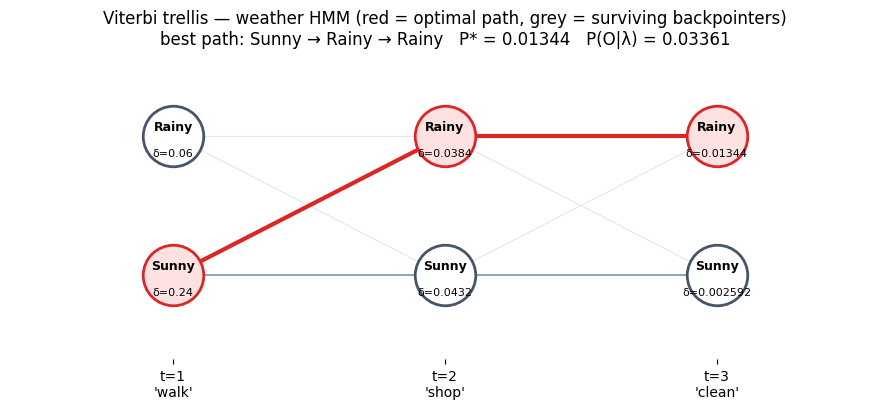

In [15]:
def draw_trellis(model, observations, ax, title):
    out = decode_for_ui(model, observations)
    T, N = len(observations), model.N
    pos = {(n["step"], n["state"]): (n["step"], N - 1 - model.states.index(n["state"])) for n in out["trellis_nodes"]}
    for e in out["trellis_edges"]:
        (x0, y0), (x1, y1) = pos[(e["step"] - 1, e["from"])], pos[(e["step"], e["to"])]
        style = dict(color="#dc2626", lw=3, zorder=2) if e["chosen"] else \
                dict(color="#94a3b8", lw=1.4, ls="-", zorder=1) if e["is_backpointer"] else dict(color="#e2e8f0", lw=0.8, zorder=0)
        ax.plot([x0, x1], [y0, y1], **style)
    for n in out["trellis_nodes"]:
        x, y = pos[(n["step"], n["state"])]
        ax.scatter(x, y, s=1900, color="#fee2e2" if n["on_best_path"] else "white", edgecolor="#dc2626" if n["on_best_path"] else "#475569", lw=2, zorder=3)
        ax.text(x, y + 0.07, n["state"], ha="center", va="center", fontsize=9, fontweight="bold", zorder=4)
        ax.text(x, y - 0.12, f"δ={n['delta']:.4g}", ha="center", va="center", fontsize=8, zorder=4)
    ax.set_xticks(range(T)); ax.set_xticklabels([f"t={t+1}\n'{o}'" for t, o in enumerate(out["observations"])])
    ax.set_yticks([]); ax.set_xlim(-0.6, T - 0.4); ax.set_ylim(-0.6, N - 0.4)
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_title(f"{title}\nbest path: {' → '.join(out['best_path'])}   P* = {out['best_path_prob']:.4g}   P(O|λ) = {out['likelihood']:.4g}")

fig, ax = plt.subplots(figsize=(9, 4.2))
draw_trellis(hmm, obs, ax, "Viterbi trellis — weather HMM (red = optimal path, grey = surviving backpointers)")
plt.tight_layout(); plt.savefig(FIG / "fig_viterbi_trellis.png", dpi=200); plt.show()

In [16]:
# Coin-toss HMM (fair vs biased coin): decoding a longer sequence, and why log space matters
coin, tosses = load_preset("coin_toss")
cv = viterbi(coin, tosses)
print(pd.DataFrame([tosses, cv["best_path"]], index=["observed", "decoded coin"]).to_string(header=False))

long_obs = ["H", "T"] * 1000
naive = np.prod([coin.B[0, 0 if o == "H" else 1] for o in long_obs])
print(f"\nDirect product over 2000 steps underflows to {naive}; log-space forward gives log P(O|λ) = {coin.forward(long_obs)['log_likelihood']:.1f}")

observed         H     T     H     H     H     H     T     H     T     T
decoded coin  Fair  Fair  Fair  Fair  Fair  Fair  Fair  Fair  Fair  Fair

Direct product over 2000 steps underflows to 0.0; log-space forward gives log P(O|λ) = -1493.8


## 6. Dual-stream timeline fusion
Two independent streams describe the same clip: Whisper speech segments and sound-model events.
Fusion turns them into one chronological caption track:

1. drop speech segments that VAD says contain almost no speech (guards against Whisper hallucinating text in silence);
2. drop low-confidence sound events, join same-label events across small gaps, drop very short ones;
3. drop events mostly covered by speech — the sound model never heard speech in training, so it labels voices confidently but wrongly;
3b. when two different labels claim the same sound, keep the more confident one;
4. merge, sort by time, and convert labels to caption tags (`clapping` → `[Applause]`).

Every removed item is kept in `dropped` with its reason, so nothing is hidden.

In [17]:
%%writefile sc_pkg/soniccaption/timeline/fusion.py
"""Dual-stream timeline fusion: Whisper speech segments + sound-model events -> one chronological caption timeline.

Pipeline (each step is deterministic, nothing is invented):
    1. Speech:  drop empty segments; if VAD segments are given, drop ASR segments that VAD says contain
                almost no speech (guards against Whisper "hallucinating" text such as "Thank you." in silence).
    2. Events:  drop events below the confidence threshold (global or per class), merge same-label events
                separated by small gaps, drop events shorter than the minimum duration.
    3. Overlap with speech: the sound model never heard speech during training (ESC-50 has no speech class), so it
                confidently mislabels voices (e.g. as dog or coughing). With policy "suppress", an event mostly covered
                by speech is dropped (optionally kept if above `keep_if_confidence`); with "keep", every event is kept
                and flagged `overlaps_speech`.
    3b. Overlap between events: when two different labels overlap, the less confident one is dropped if at least
                `event_overlap_ratio` of it lies inside the more confident one (one sound, two competing labels).
    4. Merge both streams, sort by start time (speech first on ties) and number the items.

Every dropped item is returned with the reason, so the UI/report can show what was filtered and why.

Timeline item (matches the mock API contract used by the frontend, plus provenance fields):
    {"id": "t1", "start": 0.5, "end": 4.2, "category": "speech" | "sound_event",
     "label": "Speech" | "Clapping / Applause", "display_text": "Good morning..." | "[Applause]",
     "confidence": None | 0.94, "source": "groq-whisper" | "soniccaption-esc50-resnet18",
     "overlaps_speech": bool, "words": [...]}
"""
from __future__ import annotations

from dataclasses import dataclass, field

# label -> (human-readable label, caption tag)
SOUND_TAGS: dict[str, tuple[str, str]] = {
    "clapping": ("Clapping / Applause", "[Applause]"),
    "laughing": ("Laughter", "[Laughter]"),
    "laughter": ("Laughter", "[Laughter]"),
    "coughing": ("Coughing", "[Coughing]"),
    "sneezing": ("Sneezing", "[Sneezing]"),
    "footsteps": ("Footsteps", "[Footsteps]"),
    "door_wood_knock": ("Door knock", "[Door knock]"),
    "glass_breaking": ("Glass breaking", "[Glass breaking]"),
    "siren": ("Siren", "[Siren]"),
    "dog": ("Dog barking", "[Dog barking]"),
    "rain": ("Rain", "[Rain]"),
}


@dataclass
class FusionConfig:
    event_threshold: float = 0.5                 # minimum confidence for a sound event
    class_thresholds: dict = field(default_factory=dict)   # optional per-class override, e.g. {"coughing": 0.7}
    merge_gap_s: float = 0.5                     # join same-label events separated by at most this gap
    min_event_s: float = 0.5                     # drop events shorter than this after merging
    overlap_policy: str = "suppress"             # "suppress" or "keep"
    speech_overlap_ratio: float = 0.5            # "mostly covered by speech" = at least this fraction
    keep_if_confidence: float | None = None      # if set, events at/above this confidence survive suppression
    event_overlap_ratio: float = 0.5             # resolve competing labels for the same sound
    min_vad_overlap: float = 0.2                 # ASR segment needs this fraction inside VAD speech
    duration: float | None = None                # clip length; times are clipped to [0, duration]


def _overlap(a0: float, a1: float, b0: float, b1: float) -> float:
    return max(0.0, min(a1, b1) - max(a0, b0))


def _covered(start: float, end: float, intervals: list[dict]) -> float:
    """Fraction of [start, end] covered by the union of `intervals` (which may overlap each other)."""
    if end <= start:
        return 0.0
    spans = sorted((max(start, i["start"]), min(end, i["end"])) for i in intervals if i["end"] > start and i["start"] < end)
    total, cur0, cur1 = 0.0, None, None
    for s, e in spans:
        if cur1 is None or s > cur1:
            if cur1 is not None:
                total += cur1 - cur0
            cur0, cur1 = s, e
        else:
            cur1 = max(cur1, e)
    if cur1 is not None:
        total += cur1 - cur0
    return total / (end - start)


def _clip(t: float, duration: float | None) -> float:
    t = max(0.0, float(t))
    return min(t, duration) if duration is not None else t


def merge_events(events: list[dict], gap_s: float) -> list[dict]:
    """Join events with the same label when they overlap or the gap between them is <= gap_s."""
    merged: list[dict] = []
    for e in sorted(events, key=lambda e: (e["label"], e["start"])):
        last = merged[-1] if merged else None
        if last and last["label"] == e["label"] and e["start"] - last["end"] <= gap_s:
            last["end"] = max(last["end"], e["end"])
            last["confidence"] = max(last["confidence"], e["confidence"])
        else:
            merged.append(dict(e))
    return sorted(merged, key=lambda e: e["start"])


def fuse_timeline(speech_segments: list[dict], sound_events: list[dict], vad_segments: list[dict] | None = None,
                  config: FusionConfig | None = None, speech_source: str = "whisper") -> dict:
    """Fuse the two streams. Returns {"timeline": [...], "dropped": [...], "stats": {...}}."""
    cfg = config or FusionConfig()
    if cfg.overlap_policy not in ("suppress", "keep"):
        raise ValueError("overlap_policy must be 'suppress' or 'keep'.")
    dropped: list[dict] = []

    # 1. speech stream
    speech = []
    for s in speech_segments:
        start, end = _clip(s["start"], cfg.duration), _clip(s["end"], cfg.duration)
        text = (s.get("text") or "").strip()
        if not text or end <= start:
            dropped.append({"item": s, "reason": "empty or zero-length speech segment"})
            continue
        if vad_segments is not None and _covered(start, end, vad_segments) < cfg.min_vad_overlap:
            dropped.append({"item": s, "reason": "VAD found almost no speech here (possible ASR hallucination)"})
            continue
        speech.append({"start": start, "end": end, "text": text, "words": s.get("words", [])})

    # 2. sound-event stream
    kept = []
    for e in sound_events:
        thr = cfg.class_thresholds.get(e["label"], cfg.event_threshold)
        if e["confidence"] < thr:
            dropped.append({"item": e, "reason": f"confidence {e['confidence']:.2f} below threshold {thr:.2f}"})
        else:
            kept.append({**e, "start": _clip(e["start"], cfg.duration), "end": _clip(e["end"], cfg.duration)})
    events = []
    for e in merge_events(kept, cfg.merge_gap_s):
        if e["end"] - e["start"] < cfg.min_event_s:
            dropped.append({"item": e, "reason": f"shorter than {cfg.min_event_s:.2f} s"})
        else:
            events.append(e)

    # 3. overlap with speech
    final_events = []
    for e in events:
        ratio = _covered(e["start"], e["end"], speech)
        e["overlaps_speech"] = ratio > 0
        very_confident = cfg.keep_if_confidence is not None and e["confidence"] >= cfg.keep_if_confidence
        if cfg.overlap_policy == "suppress" and ratio >= cfg.speech_overlap_ratio and not very_confident:
            dropped.append({"item": e, "reason": f"{ratio:.0%} covered by speech (likely the voice, not a sound event)"})
        else:
            final_events.append(e)

    # 3b. competing labels for the same sound: keep the more confident one
    resolved = []
    for e in sorted(final_events, key=lambda e: -e["confidence"]):
        dur = e["end"] - e["start"]
        rival = next((r for r in resolved if r["label"] != e["label"]
                      and _overlap(e["start"], e["end"], r["start"], r["end"]) >= cfg.event_overlap_ratio * dur), None)
        if rival:
            dropped.append({"item": e, "reason": f"overlaps a more confident '{rival['label']}' event ({rival['confidence']:.2f})"})
        else:
            resolved.append(e)
    final_events = sorted(resolved, key=lambda e: e["start"])

    # 4. merge and sort
    items = [{"start": round(s["start"], 3), "end": round(s["end"], 3), "category": "speech", "label": "Speech",
              "display_text": s["text"], "confidence": None, "source": speech_source,
              "overlaps_speech": False, "words": s["words"]} for s in speech]
    for e in final_events:
        label, tag = SOUND_TAGS.get(e["label"], (e["label"].replace("_", " ").title(),
                                                 f"[{e['label'].replace('_', ' ').title()}]"))
        items.append({"start": round(e["start"], 3), "end": round(e["end"], 3), "category": "sound_event",
                      "label": label, "display_text": tag, "confidence": round(float(e["confidence"]), 3),
                      "source": e.get("model", "sound-model"), "overlaps_speech": e["overlaps_speech"], "words": []})
    items.sort(key=lambda i: (i["start"], i["category"] != "speech", i["end"]))
    for n, it in enumerate(items, 1):
        it["id"] = f"t{n}"
    timeline = [{"id": it.pop("id"), **it} for it in items]

    stats = {"speech_items": len(speech), "sound_items": len(final_events), "dropped": len(dropped),
             "speech_seconds": round(sum(s["end"] - s["start"] for s in speech), 2)}
    return {"timeline": timeline, "dropped": dropped, "stats": stats}

Writing sc_pkg/soniccaption/timeline/fusion.py


In [18]:
from soniccaption.timeline.fusion import fuse_timeline, FusionConfig

fused = fuse_timeline(asr_demo["segments"], raw_events, vad_segments=vad_segments,
                      config=FusionConfig(duration=DURATION), speech_source=asr_demo["provider"])
timeline = fused["timeline"]
print("FINAL TIMELINE"); print(pd.DataFrame(timeline)[["id", "start", "end", "category", "display_text", "confidence", "source"]].to_string(index=False))
print("\nDROPPED"); print(pd.DataFrame([{**d["item"], "reason": d["reason"]} for d in fused["dropped"]]).drop(columns=["words", "model"], errors="ignore").to_string(index=False) if fused["dropped"] else "  (none)")
print("\nStats:", fused["stats"])

FINAL TIMELINE
id  start   end    category                                                                                                 display_text  confidence                      source
t1    0.0 11.38      speech And so, my fellow Americans, ask not what your country can do for you, ask what you can do for your country.         NaN                groq-whisper
t2   11.0 15.00 sound_event                                                                                                   [Applause]       0.996 soniccaption-esc50-resnet18
t3   17.0 19.00 sound_event                                                                                                 [Door knock]       0.917 soniccaption-esc50-resnet18

DROPPED
 start  end           label  confidence                                                       reason overlaps_speech
  13.5 15.5  glass_breaking       0.465                         confidence 0.47 below threshold 0.50             NaN
  14.0 16.0       footsteps       

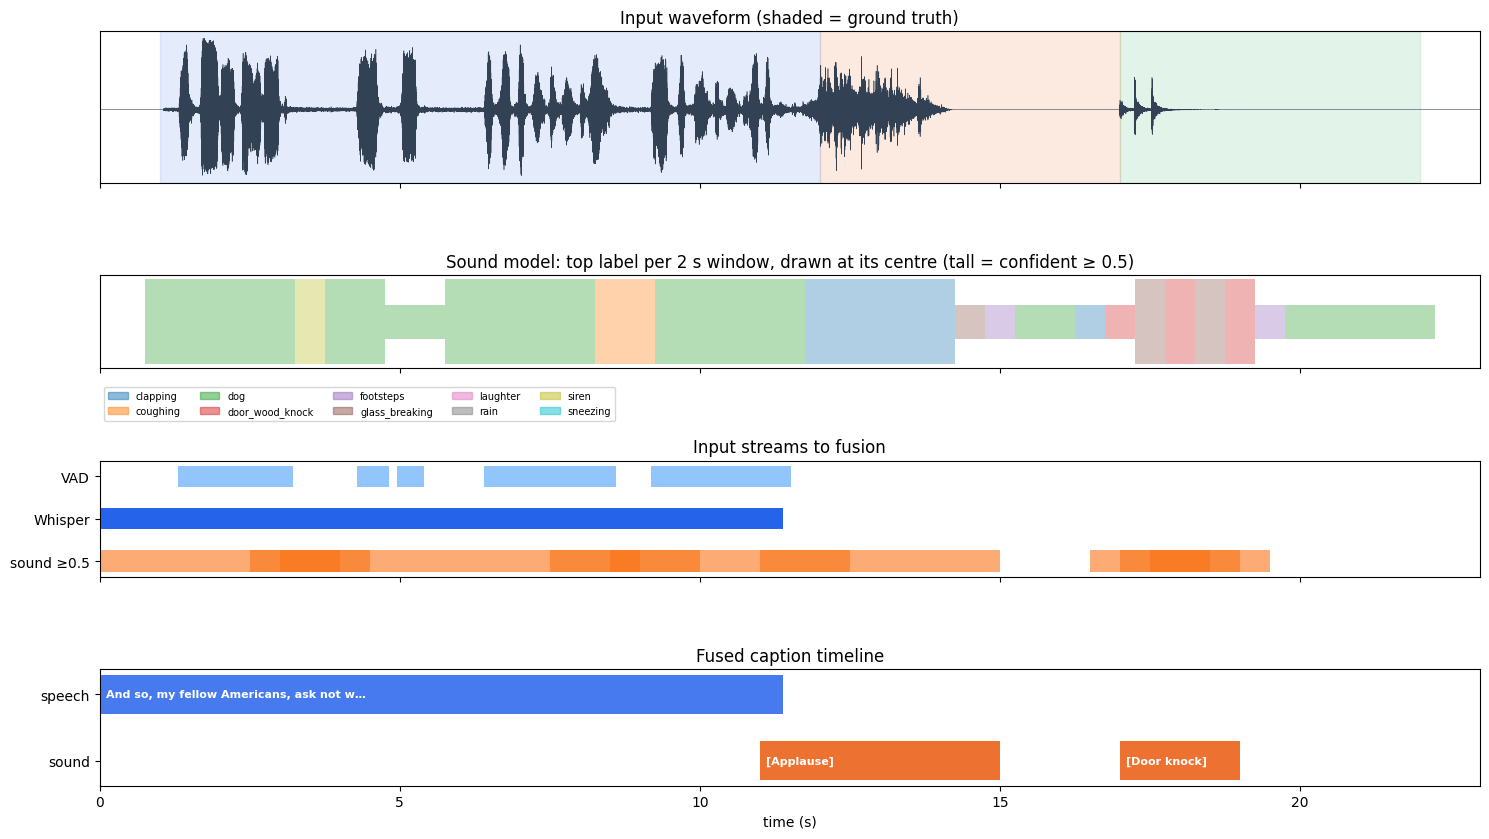

In [19]:
COLORS = {"speech": "#2563eb", "clapping": "#ea580c", "door_wood_knock": "#16a34a"}
fig, axes = plt.subplots(4, 1, figsize=(15, 8.5), sharex=True, gridspec_kw={"height_ratios": [1.3, 0.8, 1, 1]})
ax = axes[0]; ax.plot(np.arange(len(demo)) / SR, demo, lw=0.4, color="#334155")
for name, s, e in truth:
    if name != "silence": ax.axvspan(s, e, color=COLORS[name], alpha=0.12)
ax.set_title("Input waveform (shaded = ground truth)"); ax.set_yticks([])

ax = axes[1]
for t0, top in wins:
    ax.barh(0, 0.5, left=t0 + 0.75, height=0.5 if top["score"] >= 0.5 else 0.2, color=plt.cm.tab10(sound_model.labels.index(top["label"])), alpha=0.35)
ax.set_title("Sound model: top label per 2 s window, drawn at its centre (tall = confident ≥ 0.5)"); ax.set_yticks([])
handles = [plt.Rectangle((0, 0), 1, 1, color=plt.cm.tab10(i), alpha=0.5) for i in range(len(sound_model.labels))]
ax.legend(handles, sound_model.labels, ncol=5, fontsize=7, loc="upper left", bbox_to_anchor=(0, -0.15))

ax = axes[2]
for s in vad_segments: ax.barh(1, s["end"] - s["start"], left=s["start"], height=0.5, color="#93c5fd")
for s in asr_demo["segments"]: ax.barh(0, s["end"] - s["start"], left=s["start"], height=0.5, color="#2563eb")
for e in raw_events:
    if e["confidence"] >= 0.5: ax.barh(-1, e["end"] - e["start"], left=e["start"], height=0.5, color="#f97316", alpha=0.6)
ax.set_yticks([1, 0, -1]); ax.set_yticklabels(["VAD", "Whisper", "sound ≥0.5"]); ax.set_title("Input streams to fusion")

ax = axes[3]
for it in timeline:
    y, c = (1, "#2563eb") if it["category"] == "speech" else (0, "#ea580c")
    ax.barh(y, it["end"] - it["start"], left=it["start"], height=0.6, color=c, alpha=0.85)
    txt = it["display_text"] if it["category"] != "speech" else (it["display_text"][:38] + "…" if len(it["display_text"]) > 40 else it["display_text"])
    ax.text(it["start"] + 0.1, y, txt, va="center", fontsize=8, color="white", fontweight="bold", clip_on=True)
ax.set_yticks([1, 0]); ax.set_yticklabels(["speech", "sound"]); ax.set_title("Fused caption timeline"); ax.set_xlabel("time (s)")
ax.set_xlim(0, DURATION)
plt.tight_layout(); plt.savefig(FIG / "fig_fused_timeline.png", dpi=200, bbox_inches="tight"); plt.show()

In [20]:
def srt_time(t):
    ms = int(round(t * 1000)); h, ms = divmod(ms, 3_600_000); m, ms = divmod(ms, 60_000); s, ms = divmod(ms, 1000)
    return f"{h:02d}:{m:02d}:{s:02d},{ms:03d}"

srt = "\n".join(f"{n}\n{srt_time(it['start'])} --> {srt_time(it['end'])}\n{it['display_text']}\n" for n, it in enumerate(timeline, 1))
Path("demo_captions.srt").write_text(srt); print(srt)

1
00:00:00,000 --> 00:00:11,380
And so, my fellow Americans, ask not what your country can do for you, ask what you can do for your country.

2
00:00:11,000 --> 00:00:15,000
[Applause]

3
00:00:17,000 --> 00:00:19,000
[Door knock]



## 7. Summary for the report

In [21]:
summary = {
    "asr_provider": asr_jfk["provider"], "jfk_wer": round(res["wer"], 4), "jfk_cer": round(cer(JFK_REF, asr_jfk["text"]), 4),
    "corpus_wer": round(float(corpus_wer), 4), "wer_reference_words": int(total.N),
    "vad_segments": vad_segments, "vad_speech_ratio": speech_ratio(vad_segments, DURATION),
    "sound_model": sound_model.name, "hmm_weather_best_path": v["best_path"], "hmm_weather_best_prob": v["best_path_prob"],
    "hmm_weather_likelihood": f["likelihood"], "timeline": timeline, "dropped_reasons": [d["reason"] for d in fused["dropped"]],
}
Path("notebook03_summary.json").write_text(json.dumps(summary, indent=2, default=float))
print(json.dumps({k: v for k, v in summary.items() if k not in ("timeline", "vad_segments")}, indent=2, default=float))
print("\nFigures:", sorted(p.name for p in FIG.iterdir()))

{
  "asr_provider": "groq-whisper",
  "jfk_wer": 0.0,
  "jfk_cer": 0.0,
  "corpus_wer": 0.0,
  "wer_reference_words": 22,
  "vad_speech_ratio": 0.323,
  "sound_model": "soniccaption-esc50-resnet18",
  "hmm_weather_best_path": [
    "Sunny",
    "Rainy",
    "Rainy"
  ],
  "hmm_weather_best_prob": 0.013439999999999999,
  "hmm_weather_likelihood": 0.033611999999999996,
  "dropped_reasons": [
    "confidence 0.47 below threshold 0.50",
    "confidence 0.32 below threshold 0.50",
    "confidence 0.26 below threshold 0.50",
    "confidence 0.40 below threshold 0.50",
    "91% covered by speech (likely the voice, not a sound event)",
    "100% covered by speech (likely the voice, not a sound event)",
    "100% covered by speech (likely the voice, not a sound event)",
    "overlaps a more confident 'door_wood_knock' event (0.92)"
  ]
}

Figures: ['fig_fused_timeline.png', 'fig_vad_segments.png', 'fig_viterbi_trellis.png']
